Dataset Shape: (10000, 14)

First 5 rows:
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7596 - loss: 0.5480 - val_accuracy: 0.8087 - val_loss: 0.4554
Epoch 2/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7962 - loss: 0.4635 - val_accuracy: 0.8250 - val_loss: 0.4218
Epoch 3/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8051 - loss: 0.4456 - val_accuracy: 0.8363 - val_loss: 0.4069
Epoch 4/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8119 - loss: 0.4323 - val_accuracy: 0.8438 - val_loss: 0.3959
Epoch 5/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8179 - loss: 0.4241 - val_accuracy: 0.8400 - val_loss: 0.3849
Epoch 6/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8308 - loss: 0.4160 - val_accuracy: 0.8450 - val_loss: 0.3737
Epoch 7/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8339 - loss: 0.4017 - val_accuracy: 0.8575 - val_loss: 0.3610
Epoch 8/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8375 - loss: 0.3899 - val_accuracy: 0.8537 - val_

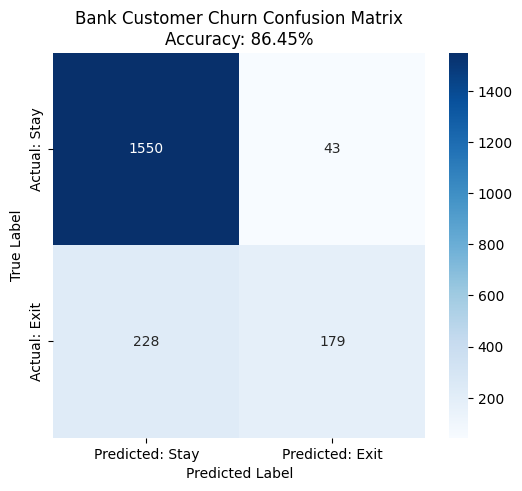

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# -----------------------------------------------------------
# 1. Read the Dataset
# -----------------------------------------------------------
# Dataset: Churn_Modelling.csv (10,000 samples, 14 features)
df = pd.read_csv("Churn_Modelling.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# -----------------------------------------------------------
# 2. Distinguish Feature and Target Set
# -----------------------------------------------------------
# RowNumber, CustomerId, Surname are non-predictive identifiers; Exited is the target
X = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])
y = df["Exited"]

# Encode categorical variables:
# Gender: Binary encoding (Female: 0, Male: 1)
le = LabelEncoder()
X["Gender"] = le.fit_transform(X["Gender"])

# Geography: One-Hot Encoding (France, Spain, Germany)
ct = ColumnTransformer(
    transformers=[("encoder", OneHotEncoder(drop="first"), ["Geography"])],
    remainder="passthrough"
)
X = ct.fit_transform(X)

# Split into Training and Test Sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------------------------------------
# 3. Normalize the Train and Test Data
# -----------------------------------------------------------
# Standardize features to mean = 0 and unit variance
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# -----------------------------------------------------------
# 4. Initialize and Build the Neural Network Model
# -----------------------------------------------------------
classifier = Sequential()

# Input & First Hidden Layer with Dropout (prevent overfitting)
classifier.add(Dense(units=16, activation="relu", input_dim=X_train.shape[1]))
classifier.add(Dropout(0.1))

# Second Hidden Layer
classifier.add(Dense(units=8, activation="relu"))
classifier.add(Dropout(0.1))

# Output Layer (Binary classification: sigmoid activation)
classifier.add(Dense(units=1, activation="sigmoid"))

# Compiling the ANN
classifier.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Training the Model
history = classifier.fit(
    X_train,
    y_train,
    batch_size=32,
    epochs=50,
    validation_split=0.1,
    verbose=1
)

# -----------------------------------------------------------
# 5. Evaluate: Accuracy Score and Confusion Matrix
# -----------------------------------------------------------
# Predict probabilities and convert to binary classes (threshold = 0.5)
y_pred_prob = classifier.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# Accuracy Score
acc = accuracy_score(y_test, y_pred)
print(f"\nFinal Test Accuracy: {acc * 100:.2f}%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Retained (0)", "Exited (1)"]))

# Visualizing Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted: Stay", "Predicted: Exit"],
            yticklabels=["Actual: Stay", "Actual: Exit"])
plt.title(f"Bank Customer Churn Confusion Matrix\nAccuracy: {acc * 100:.2f}%")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()